# Análise de Qualidade Textual e Modelagem Preditiva de Leis Federais (LegislaML)

Este notebook apresenta a Análise Exploratória de Dados (EDA) e os resultados dos modelos de Machine Learning treinados para avaliar a qualidade textual, prever o risco de veto e estimar a instabilidade de leis federais brasileiras (2020-2026).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import os

## 1. Carregamento dos Dados

Carregamos a base de dados com as features linguísticas e metadados processados das 420 leis.

In [2]:
df = pd.read_csv('../data/processed/leis_features.csv')
print(f"Linhas: {df.shape[0]}, Colunas: {df.shape[1]}")
df.head()

Linhas: 420, Colunas: 15


,id,tipo,numero,ano,data,ementa,flesch,palavras_por_sentenca,sentencas_por_artigo,densidade_referencias,ttr,proporcao_termos_tecnicos,teve_veto,instavel,score_qualidade
0,33037478,LCP,176,2020,29/12/2020,Institui transferências obrigatórias da União ...,28.768918,51.421053,1.117647,0.015353,0.333675,0.012282,0,0,3.747232
1,32810713,LCP,175,2020,23/09/2020,Dispõe sobre o padrão nacional de obrigação ac...,22.004186,46.208333,1.454545,0.008566,0.240757,0.010370,0,1,3.408237
2,32530069,LCP,174,2020,05/08/2020,Autoriza a extinção de créditos tributários ap...,31.734192,41.909091,1.222222,0.010846,0.381779,0.010846,0,0,5.013098
3,32218505,LCP,173,2020,27/05/2020,Estabelece o Programa Federativo de Enfrentame...,0.000000,85.195122,1.242424,0.015173,0.219296,0.012024,1,1,0.335402
4,32111870,LCP,172,2020,15/04/2020,Dispõe sobre a transposição e a transferência ...,25.611667,38.888889,1.285714,0.000000,0.437143,0.005714,0,1,6.429523


## 2. Análise Exploratória (EDA)

### 2.1. Distribuição do Score de Qualidade Textual

O score de qualidade é uma fórmula matemática baseada em legibilidade Flesch, concisão e densidade de referências.

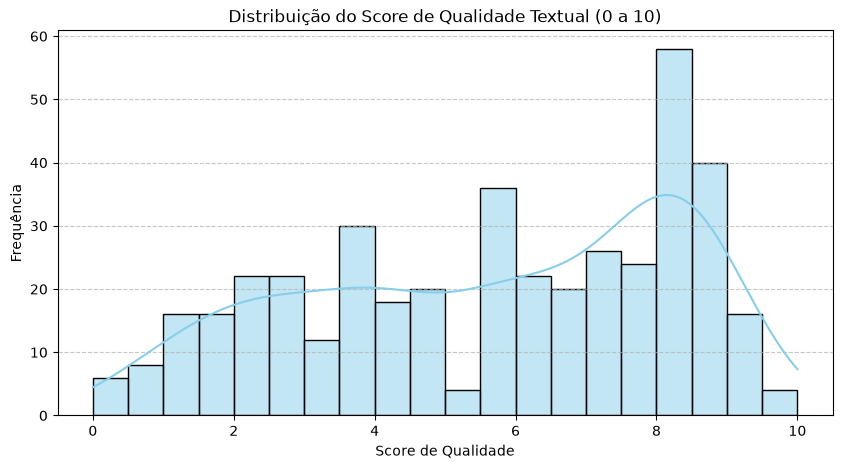

In [3]:
plt.figure(figsize=(10, 5))
sns.histplot(df['score_qualidade'], bins=20, kde=True, color='skyblue')
plt.title('Distribuição do Score de Qualidade Textual (0 a 10)')
plt.xlabel('Score de Qualidade')
plt.ylabel('Frequência')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 2.2. Mapa de Calor de Correlação (Heatmap)

O mapa de calor exibe o **Coeficiente de Correlação de Pearson** entre cada par de métricas, variando de **-1,00 a +1,00**:
*   **Próximo a +1,00 (Tons de Vermelho):** Correlação positiva forte. Quando uma variável sobe, a outra também sobe proporcionalmente.
*   **Próximo a -1,00 (Tons de Azul):** Correlação negativa forte. As variáveis são inversamente proporcionais (quando uma sobe, a outra desce).
*   **Próximo a 0,00 (Tons Claros/Brancos):** Variáveis independentes que não possuem relação linear.

*Exemplo Prático:* O Índice Flesch e a média de palavras por sentença possuem forte correlação negativa. Isso comprova matematicamente que sentenças mais longas diminuem a legibilidade e a clareza textual das leis.

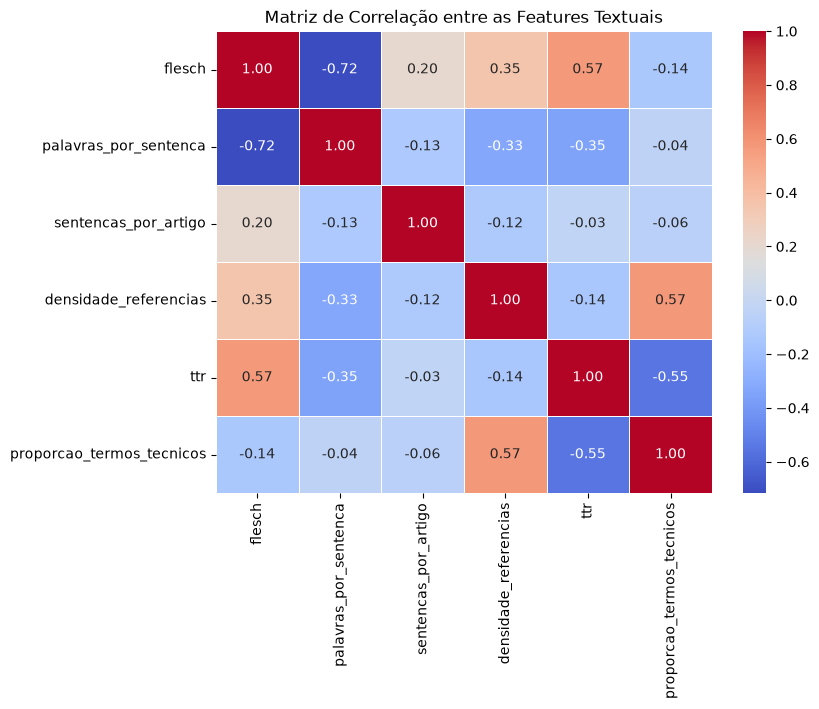

In [4]:
feature_cols = [
    'flesch',
    'palavras_por_sentenca',
    'sentencas_por_artigo',
    'densidade_referencias',
    'ttr',
    'proporcao_termos_tecnicos'
]
plt.figure(figsize=(8, 6))
sns.heatmap(df[feature_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlação entre as Features Textuais')
plt.show()

## 3. Desempenho dos Modelos de Machine Learning

Carregamos as métricas de classificação geradas pela modelagem preditiva.

In [5]:
with open('../data/processed/model_metrics.json', 'r', encoding='utf-8') as f:
    metrics = json.load(f)
print(json.dumps(metrics, indent=4))

{
    "teve_veto": {
        "best_model": "random_forest",
        "classifiers": {
            "random_forest": {
                "cv_f1_macro_mean": 0.8880325169770142,
                "test_accuracy": 0.9761904761904762,
                "test_f1_macro": 0.969208211143695,
                "confusion_matrix": [
                    [
                        61,
                        2
                    ],
                    [
                        0,
                        21
                    ]
                ],
                "precision_class_1": 0.9130434782608695,
                "recall_class_1": 1.0
            },
            "svm": {
                "cv_f1_macro_mean": 0.7380105889471616,
                "test_accuracy": 0.8690476190476191,
                "test_f1_macro": 0.8225465719224121,
                "confusion_matrix": [
                    [
                        58,
                        5
                    ],
                    [
                 

## 4. Importância das Features (Feature Importance)

A **Importância das Features** indica o quanto o modelo Random Forest dependeu de cada variável para fazer suas decisões de divisão nas árvores:
*   O **eixo horizontal** mostra a importância relativa (percentual de 0 a 1).
*   A feature com a **barra mais longa** é o fator de escrita mais determinante para o algoritmo classificar a lei como de risco de veto ou instabilidade.

Isso permite ao gestor identificar quais falhas de redação legislativa mais influenciam nas consequências práticas da lei no mundo real.

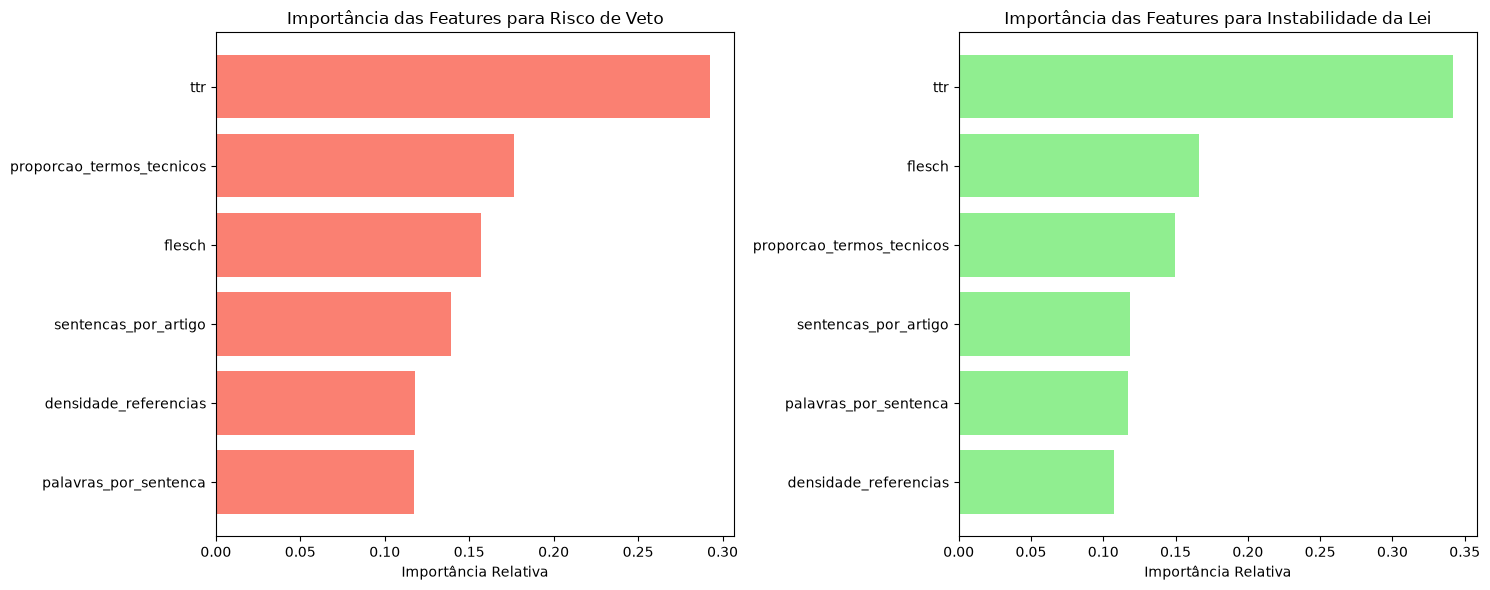

In [6]:
model_veto = joblib.load('../data/models/model_teve_veto.joblib')
model_instavel = joblib.load('../data/models/model_instavel.joblib')

importances_veto = model_veto.named_steps['classifier'].feature_importances_
importances_instavel = model_instavel.named_steps['classifier'].feature_importances_

df_imp_veto = pd.DataFrame({'feature': feature_cols, 'importancia': importances_veto}).sort_values('importancia', ascending=True)
df_imp_instavel = pd.DataFrame({'feature': feature_cols, 'importancia': importances_instavel}).sort_values('importancia', ascending=True)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

ax[0].barh(df_imp_veto['feature'], df_imp_veto['importancia'], color='salmon')
ax[0].set_title('Importância das Features para Risco de Veto')
ax[0].set_xlabel('Importância Relativa')

ax[1].barh(df_imp_instavel['feature'], df_imp_instavel['importancia'], color='lightgreen')
ax[1].set_title('Importância das Features para Instabilidade da Lei')
ax[1].set_xlabel('Importância Relativa')

plt.tight_layout()
plt.show()

## 5. Matrizes de Confusão Graficamente

A **Matriz de Confusão** é uma tabela de desempenho 2x2 que compara os palpites do modelo com os dados históricos reais do conjunto de teste:
*   **Diagonal Principal (Canto Superior Esquerdo e Inferior Direito):** Representa os **acertos** do modelo (Verdadeiros Negativos e Verdadeiros Positivos).
*   **Falsos Positivos (Canto Superior Direito):** Falso Alarme (o modelo previu problema, mas a lei era estável/sem veto).
*   **Falsos Negativos (Canto Inferior Esquerdo):** O maior risco (o modelo achou que a lei seria boa e estável, mas na realidade ela sofreu veto ou alteração).

O objetivo é concentrar a maior parte das leis na diagonal principal dos acertos e manter a diagonal de erros zerada ou próxima a zero.

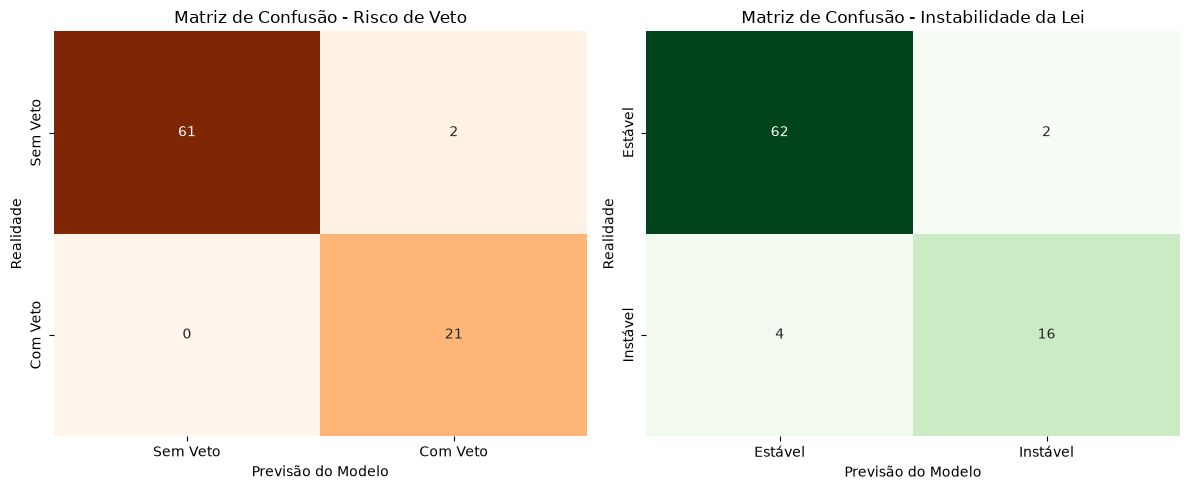

In [7]:
cm_veto = np.array(metrics['teve_veto']['classifiers']['random_forest']['confusion_matrix'])
cm_instavel = np.array(metrics['instavel']['classifiers']['random_forest']['confusion_matrix'])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(cm_veto, annot=True, fmt='d', cmap='Oranges', ax=ax[0], cbar=False,
            xticklabels=['Sem Veto', 'Com Veto'], yticklabels=['Sem Veto', 'Com Veto'])
ax[0].set_title('Matriz de Confusão - Risco de Veto')
ax[0].set_ylabel('Realidade')
ax[0].set_xlabel('Previsão do Modelo')

sns.heatmap(cm_instavel, annot=True, fmt='d', cmap='Greens', ax=ax[1], cbar=False,
            xticklabels=['Estável', 'Instável'], yticklabels=['Estável', 'Instável'])
ax[1].set_title('Matriz de Confusão - Instabilidade da Lei')
ax[1].set_ylabel('Realidade')
ax[1].set_xlabel('Previsão do Modelo')

plt.tight_layout()
plt.show()

## 6. Estudos de Caso Práticos

### 6.1. Lei com Ótima Escrita e Sem Veto/Estável
Apresentamos uma lei de alta qualidade de escrita da nossa base.

In [8]:
lei_boa = df[(df['teve_veto'] == 0) & (df['instavel'] == 0)].sort_values('score_qualidade', ascending=False).iloc[0]
print(f"ID: {lei_boa['id']} | Tipo: {lei_boa['tipo']} {lei_boa['numero']} ({lei_boa['ano']})")
print(f"Ementa: {lei_boa['ementa']}")
print(f"Score: {lei_boa['score_qualidade']:.2f}/10")
print(f"Flesch: {lei_boa['flesch']:.2f} | Palavras/Sentença: {lei_boa['palavras_por_sentenca']:.2f}")

ID: 41496865 | Tipo: LCP 218 (2025)
Ementa: Altera a Lei Complementar nº 116, de 31 de julho de 2003, para explicitar que o Imposto Sobre Serviços de Qualquer Natureza (ISS) incidente sobre os serviços de guincho intramunicipal, de guindaste e de içamento é devido no local da execução da obra.
Score: 10.00/10
Flesch: 58.27 | Palavras/Sentença: 30.40


### 6.2. Lei com Baixa Escrita, Vetada e Instável
Apresentamos uma lei que obteve baixa qualidade técnica de redação.

In [9]:
lei_ruim = df[(df['teve_veto'] == 1) & (df['instavel'] == 1)].sort_values('score_qualidade', ascending=True).iloc[0]
print(f"ID: {lei_ruim['id']} | Tipo: {lei_ruim['tipo']} {lei_ruim['numero']} ({lei_ruim['ano']})")
print(f"Ementa: {lei_ruim['ementa']}")
print(f"Score: {lei_ruim['score_qualidade']:.2f}/10")
print(f"Flesch: {lei_ruim['flesch']:.2f} | Palavras/Sentença: {lei_ruim['palavras_por_sentenca']:.2f}")

ID: 32218505 | Tipo: LCP 173 (2020)
Ementa: Estabelece o Programa Federativo de Enfrentamento ao Coronavírus SARS-CoV-2 (Covid-19), altera a Lei Complementar nº 101, de 4 de maio de 2000, e dá outras providências.
Score: 0.34/10
Flesch: 0.00 | Palavras/Sentença: 85.20
